# Media populacional de alturas com Metropolis-Hastings

Objetivo: estimar a media populacional $\mu$ e sua incerteza. Assumimos alturas independentes e normalmente distribuidas, com desvio-padrao populacional conhecido. O algoritmo abaixo constroi uma aproximacao da posterior por MCMC, passo a passo.

## 1. Dados observados e escolhas do modelo

A verossimilhanca e $y_i \sim Normal(\mu, \sigma_{dados})$. A prior e $\mu \sim Normal(\mu_{prior}, \sigma_{prior})$. Neste exemplo, $\sigma_{dados}=10$ e tratado como conhecido.

In [23]:
import numpy as np
import matplotlib.pyplot as plt

alturas = np.array([172, 180, 175, 168, 177, 174, 181, 169, 173, 176], dtype=float)
sigma_dados = 0.5
mu_prior = 170.0
sigma_prior = 5.0

print(f'Numero de pessoas: {alturas.size}')
print(f'Media amostral: {alturas.mean():.2f} cm')
print(f'Prior para mu: Normal({mu_prior:.1f}, {sigma_prior:.1f}^2)')

Numero de pessoas: 10
Media amostral: 174.50 cm
Prior para mu: Normal(170.0, 5.0^2)


## 2. Calcular a log-posterior

Metropolis-Hastings so precisa comparar posterior de dois valores de $\mu$. Trabalhamos com logaritmos: multiplicacoes de probabilidades tornam-se somas e evitamos que produtos muito pequenos virem zero (*underflow*). A constante de normalizacao da posterior nao e necessaria.

In [24]:
if alturas.size == 0 or not np.all(np.isfinite(alturas)):
    raise ValueError('As alturas devem conter ao menos um valor finito.')
if sigma_dados <= 0 or sigma_prior <= 0:
    raise ValueError('Os desvios-padrao devem ser positivos.')

# Escolhemos um valor de mu apenas para ilustrar o calculo.
mu_exemplo = 175.0
log_likelihood = np.sum(
    -np.log(sigma_dados * np.sqrt(2 * np.pi))
    - 0.5 * ((alturas - mu_exemplo) / sigma_dados) ** 2
)
log_prior = (
    -np.log(sigma_prior * np.sqrt(2 * np.pi))
    - 0.5 * ((mu_exemplo - mu_prior) / sigma_prior) ** 2
)
log_posterior = log_likelihood + log_prior

print(f'Para mu = {mu_exemplo:.1f}:')
print(f'  log-likelihood = {log_likelihood:.3f}')
print(f'  log-prior = {log_prior:.3f}')
print(f'  log-posterior (nao normalizada) = {log_posterior:.3f}')

Para mu = 175.0:
  log-likelihood = -332.258
  log-prior = -3.028
  log-posterior (nao normalizada) = -335.286


## 3. Configurar as cadeias

Em cada iteracao, propomos $\mu_{proposto} \sim Normal(\mu_{atual}, \sigma_{proposta})$. Como essa proposta e simetrica, a razao de Hastings se reduz a diferenca entre as log-posteriors. Usamos quatro valores iniciais para verificar se as cadeias chegam a mesma regiao.

In [25]:
n_iteracoes = 20_000
burn_in = 2_000
sigma_proposta = 2.0
iniciais = [155.0, 165.0, 180.0, 190.0]

if n_iteracoes <= burn_in or sigma_proposta <= 0:
    raise ValueError('Use n_iteracoes maior que burn_in e sigma_proposta positivo.')

print(f'Iteracoes por cadeia: {n_iteracoes}')
print(f'Burn-in descartado: {burn_in}')
print(f'Desvio-padrao da proposta: {sigma_proposta}')

Iteracoes por cadeia: 20000
Burn-in descartado: 2000
Desvio-padrao da proposta: 2.0


## 4. Executar Metropolis-Hastings

Para cada cadeia: propomos um novo valor, calculamos sua log-posterior, aceitamos sempre que ele for mais provavel e, caso contrario, o aceitamos com probabilidade proporcional a $\exp(\Delta)$. Se a proposta for rejeitada, repetimos o estado atual na cadeia.

In [26]:
cadeias = []
taxas_aceitacao = []

for indice_cadeia, mu_inicial in enumerate(iniciais):
    rng = np.random.default_rng(42 + indice_cadeia)
    cadeia = np.empty(n_iteracoes)
    mu_atual = mu_inicial
    aceitos = 0

    # Log-posterior do primeiro estado da cadeia.
    log_likelihood_atual = np.sum(
        -np.log(sigma_dados * np.sqrt(2 * np.pi))
        - 0.5 * ((alturas - mu_atual) / sigma_dados) ** 2
    )
    log_prior_atual = (
        -np.log(sigma_prior * np.sqrt(2 * np.pi))
        - 0.5 * ((mu_atual - mu_prior) / sigma_prior) ** 2
    )
    log_posterior_atual = log_likelihood_atual + log_prior_atual

    for t in range(n_iteracoes):
        # 1. Propor um vizinho do estado atual.
        mu_proposto = rng.normal(mu_atual, sigma_proposta)

        # 2. Calcular a log-posterior do candidato.
        log_likelihood_proposta = np.sum(
            -np.log(sigma_dados * np.sqrt(2 * np.pi))
            - 0.5 * ((alturas - mu_proposto) / sigma_dados) ** 2
        )
        log_prior_proposta = (
            -np.log(sigma_prior * np.sqrt(2 * np.pi))
            - 0.5 * ((mu_proposto - mu_prior) / sigma_prior) ** 2
        )
        log_posterior_proposta = log_likelihood_proposta + log_prior_proposta

        # 3. Aceitar ou rejeitar. log_alpha nunca e maior que zero.
        log_alpha = min(0.0, log_posterior_proposta - log_posterior_atual)
        if np.log(rng.uniform()) < log_alpha:
            mu_atual = mu_proposto
            log_posterior_atual = log_posterior_proposta
            aceitos += 1

        # 4. Guardar o estado, inclusive quando a proposta foi rejeitada.
        cadeia[t] = mu_atual

    cadeias.append(cadeia)
    taxas_aceitacao.append(aceitos / n_iteracoes)

cadeias = np.asarray(cadeias)
print(f'Taxas de aceitacao: {np.round(taxas_aceitacao, 3)}')

Taxas de aceitacao: [0.098 0.104 0.098 0.098]


## 5. Descartar burn-in e resumir a posterior

Os estados iniciais dependem da escolha arbitraria de $\mu_{inicial}$, por isso removemos o burn-in. As amostras restantes aproximam a distribuicao posterior de $\mu$. O intervalo entre os quantis 2.5% e 97.5% e um intervalo de credibilidade de 95%.

In [27]:
amostras_por_cadeia = cadeias[:, burn_in:]
amostras_posteriores = amostras_por_cadeia.ravel()
media_posterior = amostras_posteriores.mean()
dp_posterior = amostras_posteriores.std(ddof=1)
limite_inferior, limite_superior = np.quantile(amostras_posteriores, [0.025, 0.975])

print(f'Media posterior: {media_posterior:.2f} cm')
print(f'Desvio-padrao posterior: {dp_posterior:.2f} cm')
print(f'Intervalo de credibilidade de 95%: [{limite_inferior:.2f}, {limite_superior:.2f}] cm')

Media posterior: 174.49 cm
Desvio-padrao posterior: 0.16 cm
Intervalo de credibilidade de 95%: [174.19, 174.80] cm


## 6. Verificar convergencia e precisao Monte Carlo

R-hat proximo de 1 indica que as quatro cadeias tem variabilidade semelhante entre e dentro delas. O tamanho efetivo da amostra (ESS) desconta a autocorrelacao; ele determina o erro Monte Carlo da media estimada.

In [28]:
numero_cadeias, draws_por_cadeia = amostras_por_cadeia.shape
medias_das_cadeias = amostras_por_cadeia.mean(axis=1)
variancia_entre = draws_por_cadeia * np.var(medias_das_cadeias, ddof=1)
variancia_dentro = np.mean(np.var(amostras_por_cadeia, axis=1, ddof=1))
variancia_posterior_estimada = (
    (draws_por_cadeia - 1) / draws_por_cadeia * variancia_dentro
    + variancia_entre / draws_por_cadeia
)
r_hat = np.sqrt(variancia_posterior_estimada / variancia_dentro)

# ESS por cadeia, somando autocorrelacoes positivas.
ess = 0.0
for cadeia in amostras_por_cadeia:
    cadeia_centrada = cadeia - cadeia.mean()
    denominador = np.dot(cadeia_centrada, cadeia_centrada)
    soma_autocorrelacoes = 0.0
    for lag in range(1, draws_por_cadeia):
        autocorrelacao = np.dot(cadeia_centrada[:-lag], cadeia_centrada[lag:]) / denominador
        if autocorrelacao <= 0:
            break
        soma_autocorrelacoes += autocorrelacao
    ess += draws_por_cadeia / (1 + 2 * soma_autocorrelacoes)

erro_monte_carlo = dp_posterior / np.sqrt(ess)
print(f'R-hat: {r_hat:.3f}')
print(f'ESS aproximado: {ess:.0f}')
print(f'Erro Monte Carlo da media: {erro_monte_carlo:.3f} cm')

R-hat: 1.000
ESS aproximado: 4954
Erro Monte Carlo da media: 0.002 cm


## 7. Visualizar a exploracao e a PDF posterior aproximada

O grafico da esquerda mostra se as cadeias exploram a mesma regiao. O histograma normalizado da direita aproxima a PDF posterior: a proporcao de amostras em cada faixa de valores representa sua densidade posterior.

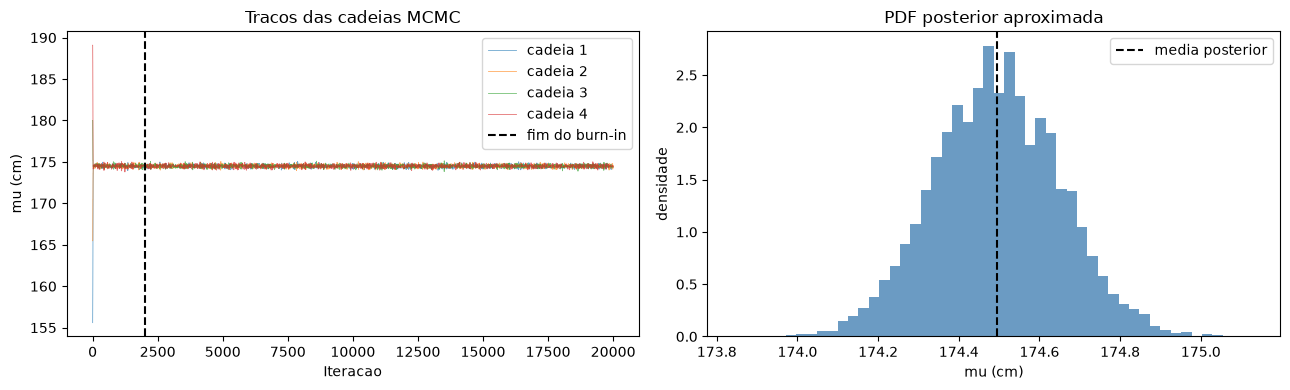

In [29]:
fig, (ax_trace, ax_pdf) = plt.subplots(1, 2, figsize=(13, 4))

for numero, cadeia in enumerate(cadeias, start=1):
    ax_trace.plot(cadeia, alpha=0.65, linewidth=0.6, label=f'cadeia {numero}')
ax_trace.axvline(burn_in, color='black', linestyle='--', label='fim do burn-in')
ax_trace.set(xlabel='Iteracao', ylabel='mu (cm)', title='Tracos das cadeias MCMC')
ax_trace.legend()

ax_pdf.hist(amostras_posteriores, bins=50, density=True, color='steelblue', alpha=0.8)
ax_pdf.axvline(media_posterior, color='black', linestyle='--', label='media posterior')
ax_pdf.set(xlabel='mu (cm)', ylabel='densidade', title='PDF posterior aproximada')
ax_pdf.legend()

plt.tight_layout()
plt.show()

## 8. Pontos efetivamente visitados

Cada marcador abaixo e um estado armazenado pela cadeia apos o burn-in. Pontos sobrepostos no mesmo valor revelam propostas rejeitadas: nesses casos a cadeia permaneceu no estado anterior.

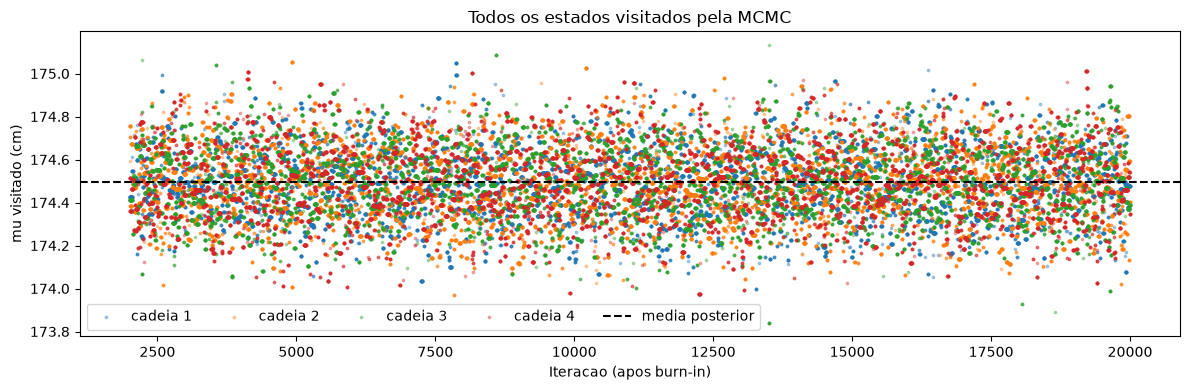

Primeiros 10 estados pos-burn-in de cada cadeia:
[[174.42586587 174.42586587 174.42586587 174.42586587 174.42586587
  174.42586587 174.42586587 174.42586587 174.42586587 174.42586587]
 [174.70591466 174.70591466 174.70591466 174.75672315 174.75672315
  174.75672315 174.75672315 174.75672315 174.75672315 174.75672315]
 [174.4111784  174.4111784  174.4111784  174.4111784  174.4111784
  174.4111784  174.4111784  174.4111784  174.4111784  174.4111784 ]
 [174.51356776 174.51356776 174.51356776 174.51356776 174.51356776
  174.51356776 174.51356776 174.51356776 174.51356776 174.36085205]]


In [30]:
fig, ax = plt.subplots(figsize=(12, 4))
iteracoes_posteriores = np.arange(burn_in, n_iteracoes)

for numero, cadeia in enumerate(amostras_por_cadeia, start=1):
    ax.scatter(
        iteracoes_posteriores, cadeia, s=3, alpha=0.35,
        label=f'cadeia {numero}'
    )

ax.axhline(media_posterior, color='black', linestyle='--', label='media posterior')
ax.set(
    xlabel='Iteracao (apos burn-in)',
    ylabel='mu visitado (cm)',
    title='Todos os estados visitados pela MCMC'
)
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

print('Primeiros 10 estados pos-burn-in de cada cadeia:')
print(amostras_por_cadeia[:, :10])

## 9. Comparar cada cadeia separadamente

Os tracos abaixo mostram a evolucao de cada cadeia sem sobreposicao. As PDFs sao histogramas normalizados das amostras apos o burn-in de cada cadeia individualmente. Se as quatro aproximacoes forem parecidas, isso reforca a evidencia de convergencia.

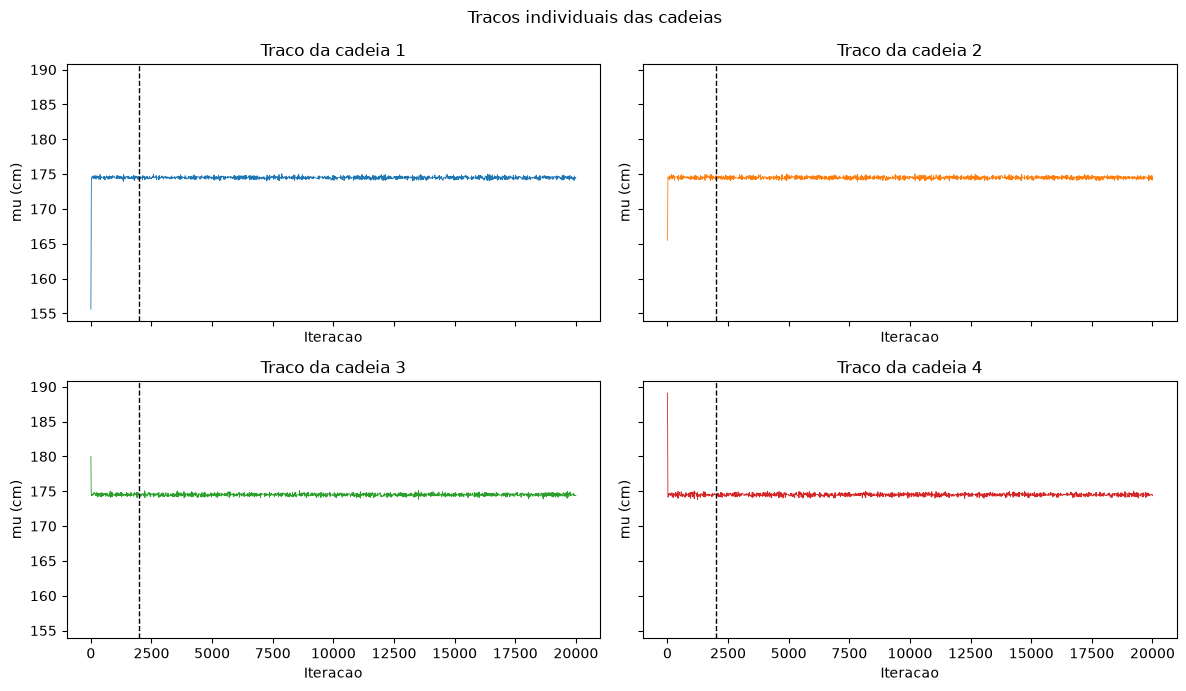

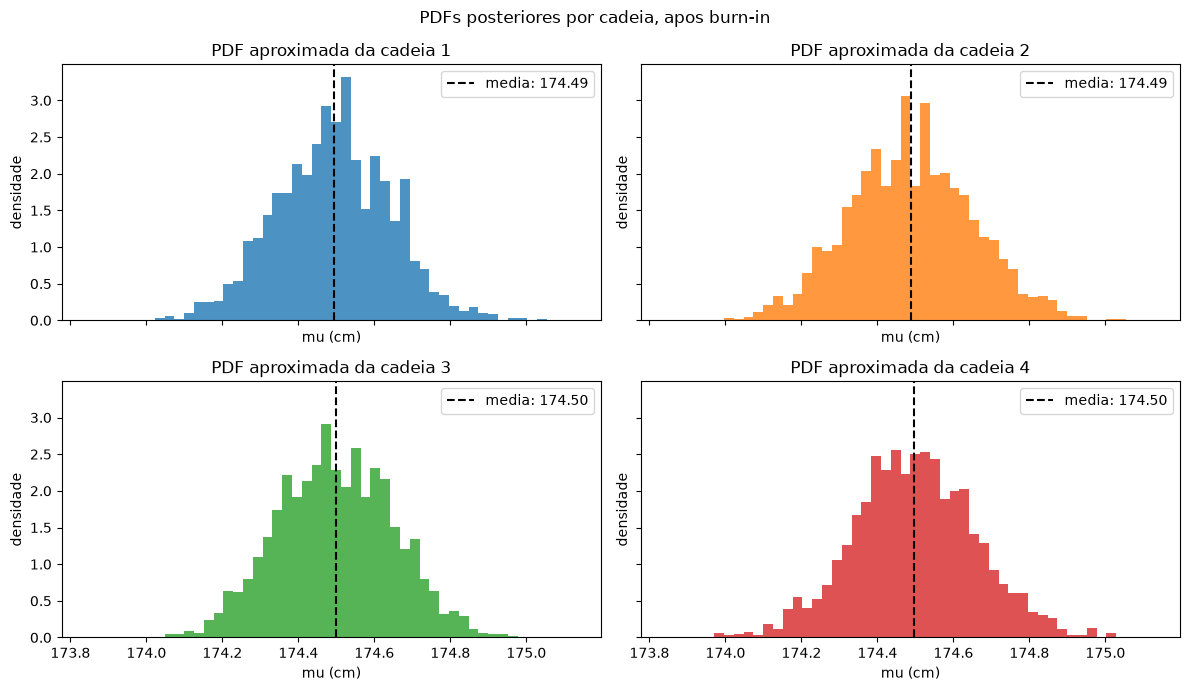

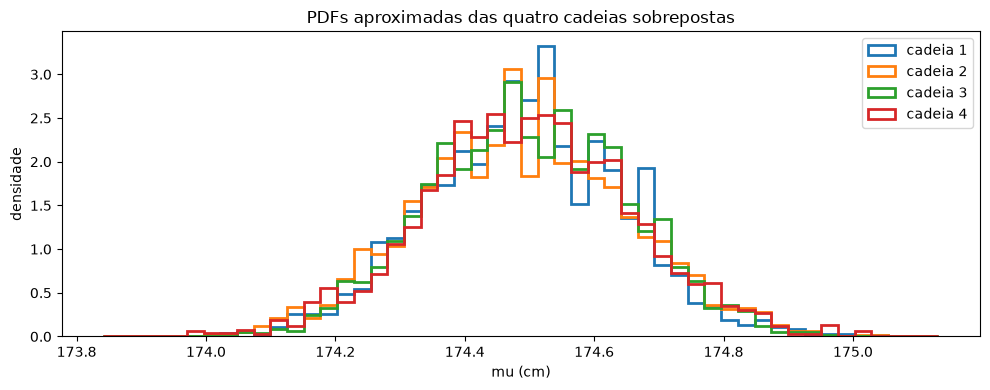

In [31]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)

for numero, (eixo, cadeia) in enumerate(zip(eixos.ravel(), cadeias), start=1):
    eixo.plot(cadeia, linewidth=0.6, color=f'C{numero - 1}')
    eixo.axvline(burn_in, color='black', linestyle='--', linewidth=1)
    eixo.set(title=f'Traco da cadeia {numero}', xlabel='Iteracao', ylabel='mu (cm)')

fig.suptitle('Tracos individuais das cadeias')
plt.tight_layout()
plt.show()

limites = (amostras_posteriores.min(), amostras_posteriores.max())
fig, eixos = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)

for numero, (eixo, cadeia) in enumerate(zip(eixos.ravel(), amostras_por_cadeia), start=1):
    eixo.hist(cadeia, bins=50, range=limites, density=True, color=f'C{numero - 1}', alpha=0.8)
    eixo.axvline(cadeia.mean(), color='black', linestyle='--', label=f'media: {cadeia.mean():.2f}')
    eixo.set(title=f'PDF aproximada da cadeia {numero}', xlabel='mu (cm)', ylabel='densidade')
    eixo.legend()

fig.suptitle('PDFs posteriores por cadeia, apos burn-in')
plt.tight_layout()
plt.show()

# Sobrepor as densidades facilita comparar as quatro cadeias diretamente.
bins_comuns = np.linspace(limites[0], limites[1], 51)
fig, ax = plt.subplots(figsize=(10, 4))
for numero, cadeia in enumerate(amostras_por_cadeia, start=1):
    ax.hist(
        cadeia, bins=bins_comuns, density=True, histtype='step', linewidth=2,
        color=f'C{numero - 1}', label=f'cadeia {numero}'
    )

ax.set(
    xlabel='mu (cm)', ylabel='densidade',
    title='PDFs aproximadas das quatro cadeias sobrepostas'
)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Atualizacao sequencial: um dado por vez

Esta secao nao usa MCMC: como a priori e a verossimilhanca sao normais e o desvio-padrao dos dados e conhecido, cada posterior pode ser calculada exatamente. Em cada painel, a curva cinza e a distribuicao antes de incluir a altura indicada; a curva azul e a posterior depois de incluir somente aquela nova observacao. A posterior de um painel se torna a priori do painel seguinte.

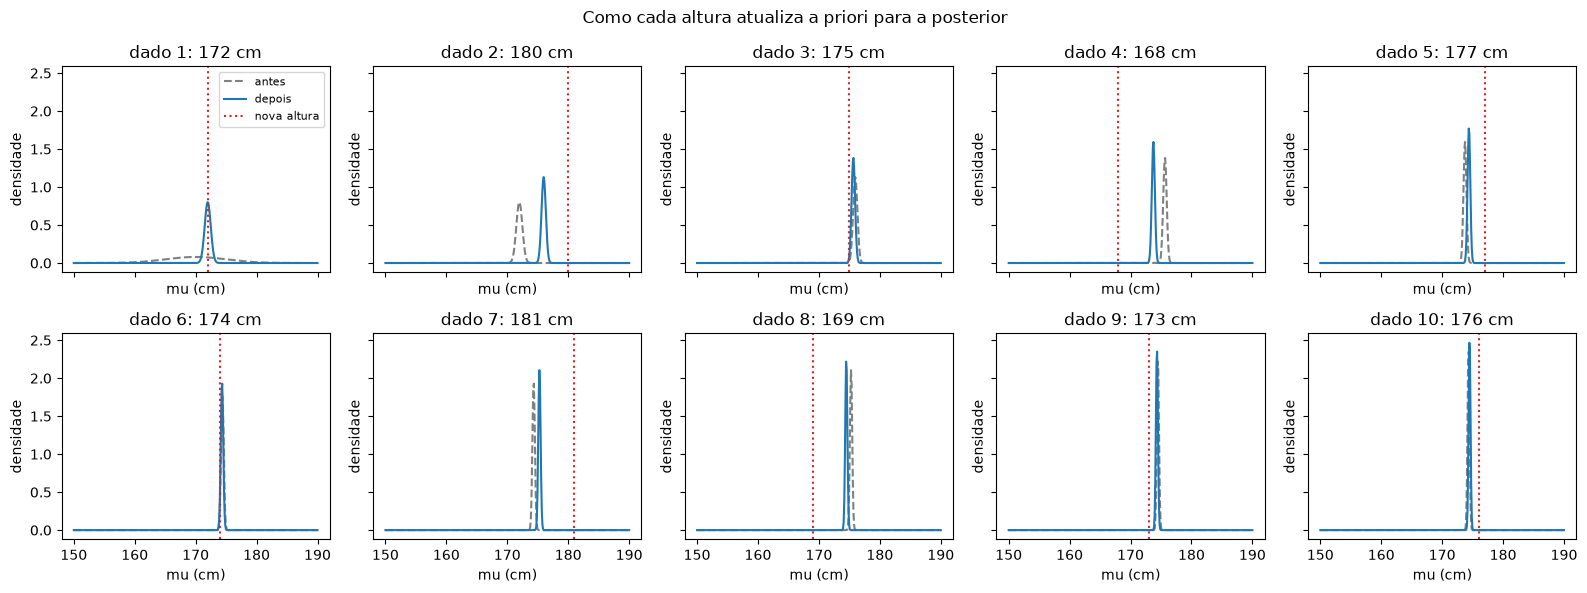

Posterior apos os 10 dados: Normal(174.50, 0.16^2)


In [32]:
# A posterior apos uma observacao Normal e tambem Normal.
media_atual = mu_prior
variancia_atual = sigma_prior ** 2
atualizacoes = []

for altura in alturas:
    media_anterior = media_atual
    variancia_anterior = variancia_atual

    # Precisao posterior = precisao anterior + precisao de uma observacao.
    variancia_atual = 1 / (1 / variancia_anterior + 1 / sigma_dados ** 2)
    media_atual = variancia_atual * (
        media_anterior / variancia_anterior + altura / sigma_dados ** 2
    )
    atualizacoes.append((altura, media_anterior, variancia_anterior, media_atual, variancia_atual))

limite_esquerdo = min(mu_prior - 4 * sigma_prior, media_atual - 4 * np.sqrt(variancia_atual))
limite_direito = max(mu_prior + 4 * sigma_prior, media_atual + 4 * np.sqrt(variancia_atual))
grade_mu = np.linspace(limite_esquerdo, limite_direito, 400)

fig, eixos = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=True)
for indice, (eixo, atualizacao) in enumerate(zip(eixos.ravel(), atualizacoes), start=1):
    altura, media_anterior, variancia_anterior, media_nova, variancia_nova = atualizacao
    dp_anterior = np.sqrt(variancia_anterior)
    dp_novo = np.sqrt(variancia_nova)
    pdf_anterior = np.exp(-0.5 * ((grade_mu - media_anterior) / dp_anterior) ** 2) / (dp_anterior * np.sqrt(2 * np.pi))
    pdf_nova = np.exp(-0.5 * ((grade_mu - media_nova) / dp_novo) ** 2) / (dp_novo * np.sqrt(2 * np.pi))

    eixo.plot(grade_mu, pdf_anterior, color='gray', linestyle='--', label='antes')
    eixo.plot(grade_mu, pdf_nova, color='C0', label='depois')
    eixo.axvline(altura, color='C3', linestyle=':', label='nova altura')
    eixo.set(title=f'dado {indice}: {altura:.0f} cm', xlabel='mu (cm)', ylabel='densidade')

eixos[0, 0].legend(fontsize=8)
fig.suptitle('Como cada altura atualiza a priori para a posterior')
plt.tight_layout()
plt.show()

print(f'Posterior apos os {alturas.size} dados: Normal({media_atual:.2f}, {np.sqrt(variancia_atual):.2f}^2)')